## Step 1: Imports and load data

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
                             roc_auc_score, f1_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

df = pd.read_csv("novagen_dataset.csv")

# One-hot columns come as True/False; convert to 0/1
bool_cols = df.select_dtypes(include="bool").columns
df[bool_cols] = df[bool_cols].astype(int)

print(df.shape)
df.head()

(9549, 23)


,Age,BMI,Blood_Pressure,Cholesterol,Glucose_Level,Heart_Rate,Sleep_Hours,Exercise_Hours,Water_Intake,Stress_Level,...,Diet,MentalHealth,PhysicalActivity,MedicalHistory,Allergies,Diet_Type__Vegan,Diet_Type__Vegetarian,Blood_Group_AB,Blood_Group_B,Blood_Group_O
0,2.0,26.0,111.0,198.0,99.0,72.0,4.0,1.0,5.0,5.0,...,1,2,1,0,1,0,1,1,0,0
1,8.0,24.0,121.0,199.0,103.0,75.0,2.0,1.0,2.0,9.0,...,1,2,1,2,2,0,0,1,0,0
2,81.0,27.0,147.0,203.0,100.0,74.0,10.0,-0.0,5.0,1.0,...,2,0,0,1,0,1,0,0,0,0
3,25.0,21.0,150.0,199.0,102.0,70.0,7.0,3.0,3.0,3.0,...,1,2,1,2,0,1,0,0,1,0
4,24.0,26.0,146.0,202.0,99.0,76.0,10.0,2.0,5.0,1.0,...,2,0,2,0,2,0,1,0,1,0


## Step 2: Basic inspection (missing values, duplicates, class balance)

In [2]:
print(df.info())
print("\nMissing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nClass balance:\n", df["Target"].value_counts(normalize=True).round(3))
df.describe().T.round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9549 entries, 0 to 9548
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    9549 non-null   float64
 1   BMI                    9549 non-null   float64
 2   Blood_Pressure         9549 non-null   float64
 3   Cholesterol            9549 non-null   float64
 4   Glucose_Level          9549 non-null   float64
 5   Heart_Rate             9549 non-null   float64
 6   Sleep_Hours            9549 non-null   float64
 7   Exercise_Hours         9549 non-null   float64
 8   Water_Intake           9549 non-null   float64
 9   Stress_Level           9549 non-null   float64
 10  Target                 9549 non-null   int64  
 11  Smoking                9549 non-null   int64  
 12  Alcohol                9549 non-null   int64  
 13  Diet                   9549 non-null   int64  
 14  MentalHealth           9549 non-null   int64  
 15  Phys

,count,mean,std,min,25%,50%,75%,max
Age,9549.0,33.81,24.57,0.0,14.0,29.0,50.0,100.0
BMI,9549.0,25.66,1.94,19.0,24.0,26.0,27.0,32.0
Blood_Pressure,9549.0,130.38,27.88,22.0,113.0,134.0,150.0,225.0
Cholesterol,9549.0,199.09,1.97,192.0,198.0,199.0,200.0,207.0
Glucose_Level,9549.0,100.23,2.16,93.0,99.0,100.0,102.0,107.0
Heart_Rate,9549.0,73.61,1.68,67.0,73.0,74.0,75.0,80.0
Sleep_Hours,9549.0,6.95,2.35,0.0,5.0,7.0,9.0,14.0
Exercise_Hours,9549.0,1.89,1.38,-0.0,1.0,2.0,3.0,8.0
Water_Intake,9549.0,3.58,1.62,-0.0,2.0,4.0,5.0,10.0
Stress_Level,9549.0,4.38,2.08,0.0,3.0,4.0,6.0,12.0


## Step 3: Check what Target = 0 and 1 mean
Class 0 is older with much higher blood pressure, so 0 = Unhealthy and 1 = Healthy.

In [3]:
df.groupby("Target")[["Age", "BMI", "Blood_Pressure", "Cholesterol", "Glucose_Level",
                      "Heart_Rate", "Stress_Level", "Smoking", "MedicalHistory"]].mean().round(2).T

Target,0,1
Age,38.70,29.32
BMI,24.82,26.43
Blood_Pressure,141.45,120.23
Cholesterol,199.76,198.48
Glucose_Level,100.39,100.08
Heart_Rate,73.73,73.51
Stress_Level,4.12,4.62
Smoking,0.99,0.99
MedicalHistory,1.01,1.00


## Step 4: Exploratory plots

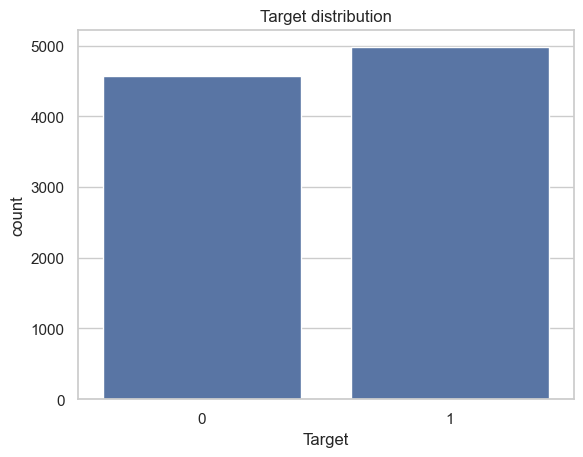

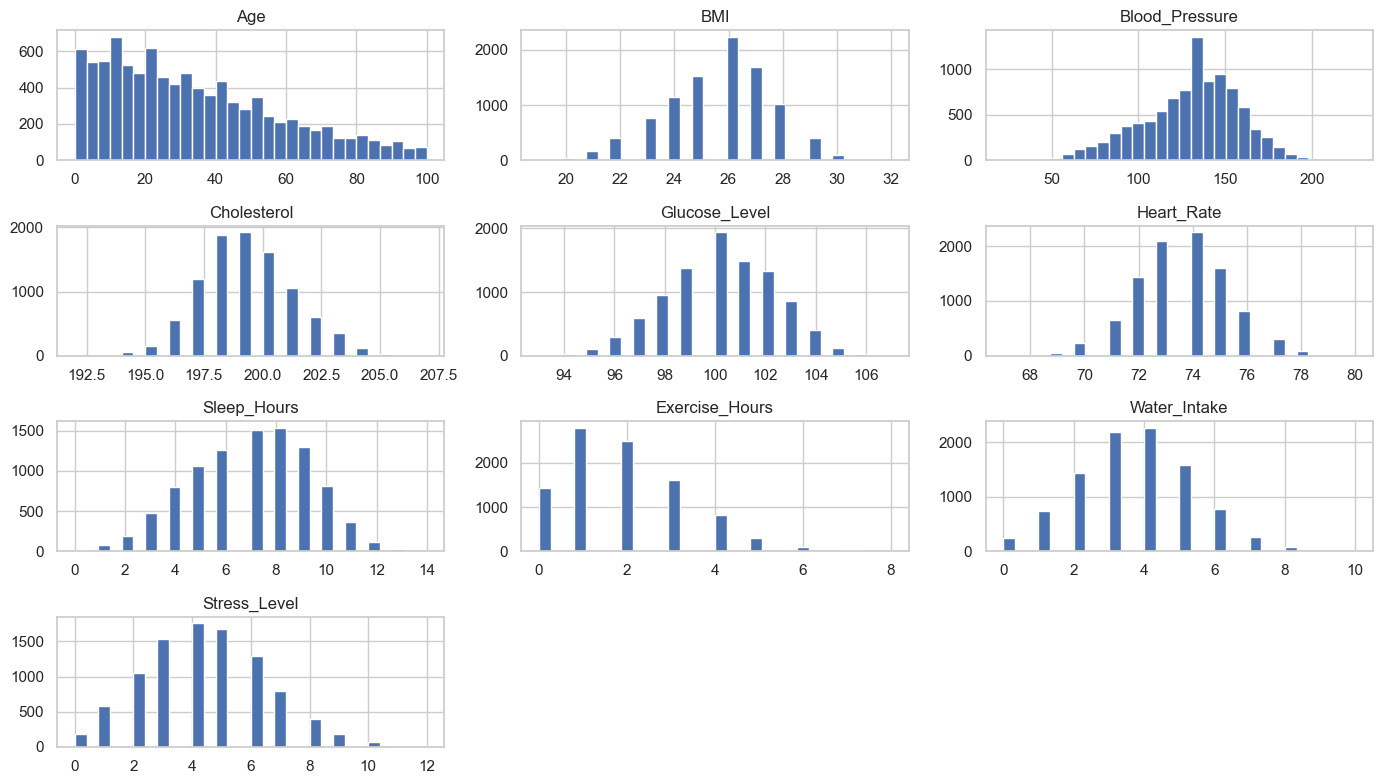

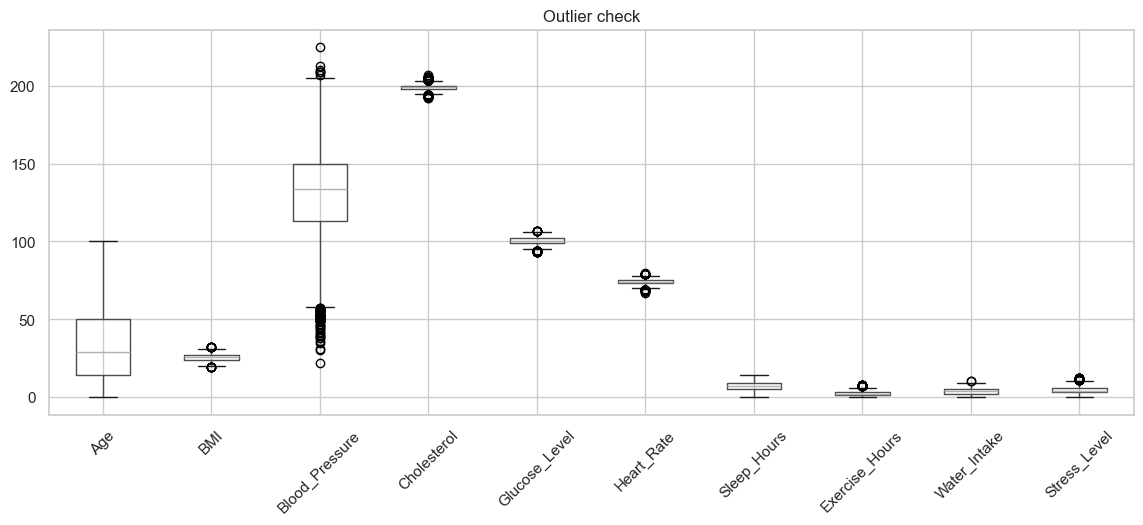

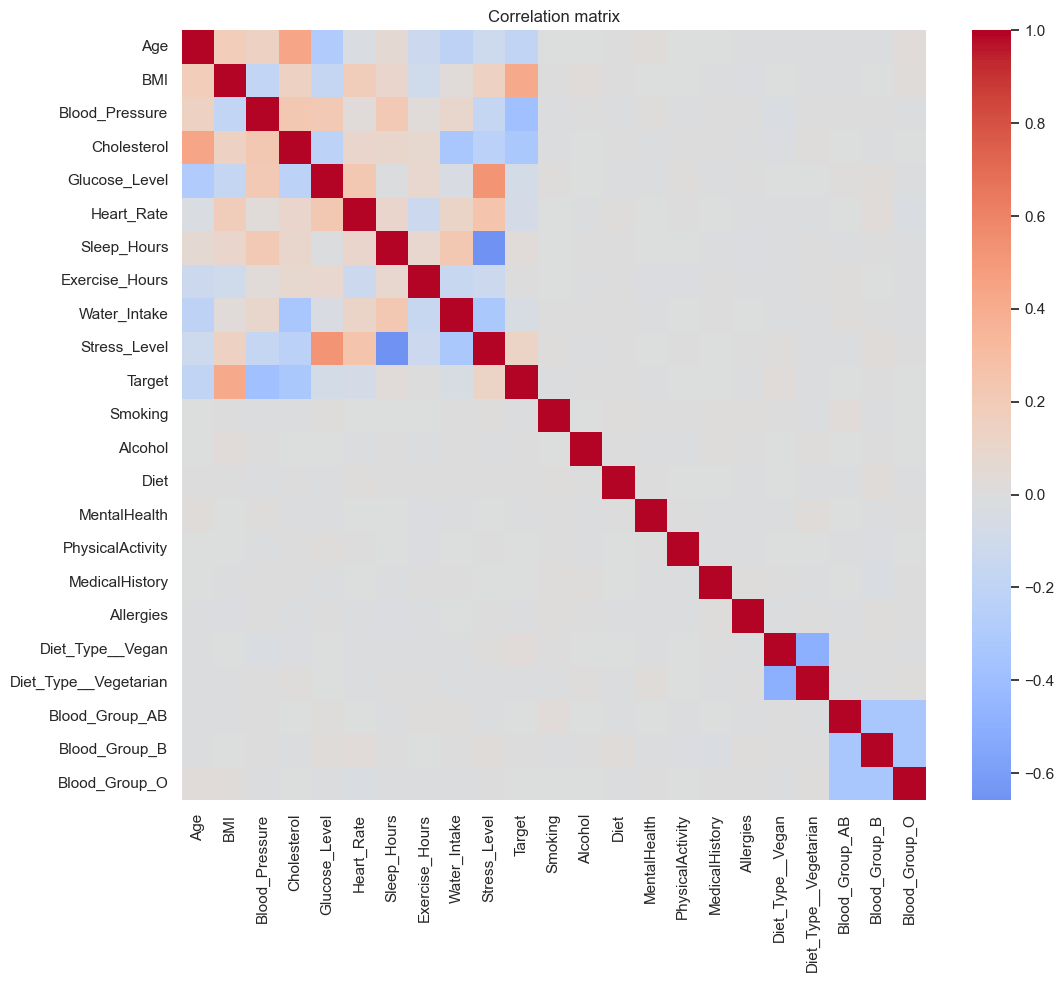

BMI               0.414
Blood_Pressure   -0.380
Cholesterol      -0.324
Age              -0.191
Stress_Level      0.119
Glucose_Level    -0.072
Heart_Rate       -0.066
Water_Intake     -0.038
Name: Target, dtype: float64


In [4]:
CONT = ["Age", "BMI", "Blood_Pressure", "Cholesterol", "Glucose_Level", "Heart_Rate",
        "Sleep_Hours", "Exercise_Hours", "Water_Intake", "Stress_Level"]

sns.countplot(x="Target", data=df)
plt.title("Target distribution"); plt.show()

df[CONT].hist(bins=30, figsize=(14, 8)); plt.tight_layout(); plt.show()

plt.figure(figsize=(14, 5)); df[CONT].boxplot(); plt.xticks(rotation=45)
plt.title("Outlier check"); plt.show()

plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

print(df.corr(numeric_only=True)["Target"].drop("Target")
        .sort_values(key=abs, ascending=False).round(3).head(8))

## Step 5: Cleaning
Remove physiologically implausible rows (this drops the 93 rows with blood pressure below 60).

In [5]:
df = df.drop_duplicates()

bounds = {"Age": (0, 110), "BMI": (10, 70), "Blood_Pressure": (60, 260),
          "Heart_Rate": (30, 220), "Glucose_Level": (30, 600), "Cholesterol": (50, 600)}
mask = pd.Series(True, index=df.index)
for col, (lo, hi) in bounds.items():
    mask &= df[col].between(lo, hi)

print("Rows removed:", int((~mask).sum()), "| rows kept:", int(mask.sum()))
df = df[mask].reset_index(drop=True)

Rows removed: 93 | rows kept: 9456


## Step 6: Train/test split and preprocessing
Scaling happens inside a pipeline, so nothing leaks from the test set.

In [6]:
X = df.drop(columns="Target")
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

prep = ColumnTransformer([("sc", StandardScaler(), CONT)], remainder="passthrough")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Train: (7564, 22) | Test: (1892, 22)


## Step 7: Baseline models (5-fold cross-validation)
This step takes a few minutes.

In [7]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=2000),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "SVM": SVC(random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
}
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("m", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name, **{s: res[f"test_{s}"].mean() for s in scoring}})
    print(f"{name:20s} F1={rows[-1]['f1']:.3f}  AUC={rows[-1]['roc_auc']:.3f}")

pd.DataFrame(rows).set_index("Model").round(3).sort_values("roc_auc", ascending=False)

LogisticRegression   F1=0.824  AUC=0.888
KNN                  F1=0.930  AUC=0.976
SVM                  F1=0.939  AUC=0.979
RandomForest         F1=0.940  AUC=0.980
GradientBoosting     F1=0.922  AUC=0.970


,accuracy,precision,recall,f1,roc_auc
Model,,,,,
RandomForest,0.937,0.932,0.948,0.940,0.980
SVM,0.936,0.930,0.948,0.939,0.979
KNN,0.928,0.930,0.931,0.930,0.976
GradientBoosting,0.918,0.914,0.929,0.922,0.970
LogisticRegression,0.815,0.811,0.837,0.824,0.888


## Step 8: Tune Random Forest

In [8]:
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions={
        "n_estimators": [200, 300],
        "max_depth": [None, 10, 15, 20],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", "log2"],
    },
    n_iter=8, cv=cv, scoring="f1", random_state=42, n_jobs=-1,
).fit(X_train, y_train)
print("RF best:", rf_search.best_params_, round(rf_search.best_score_, 3))

RF best: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None} 0.94


## Step 9: Tune SVM

In [9]:
svm_search = RandomizedSearchCV(
    Pipeline([("prep", prep), ("m", SVC(probability=True, random_state=42, cache_size=500))]),
    param_distributions={
        "m__C": [0.5, 1, 5, 10, 50],
        "m__gamma": ["scale", 0.01, 0.05, 0.1],
        "m__kernel": ["rbf"],
    },
    n_iter=6, cv=cv, scoring="f1", random_state=42, n_jobs=-1,
).fit(X_train, y_train)
print("SVM best:", svm_search.best_params_, round(svm_search.best_score_, 3))

SVM best: {'m__kernel': 'rbf', 'm__gamma': 'scale', 'm__C': 5} 0.944


## Step 10: Pick the best model and evaluate on the test set
The test set is used once, here.

Selected: SVM
              precision    recall  f1-score   support

 0 Unhealthy      0.942     0.931     0.937       914
   1 Healthy      0.936     0.947     0.942       978

    accuracy                          0.939      1892
   macro avg      0.939     0.939     0.939      1892
weighted avg      0.939     0.939     0.939      1892

ROC AUC: 0.985


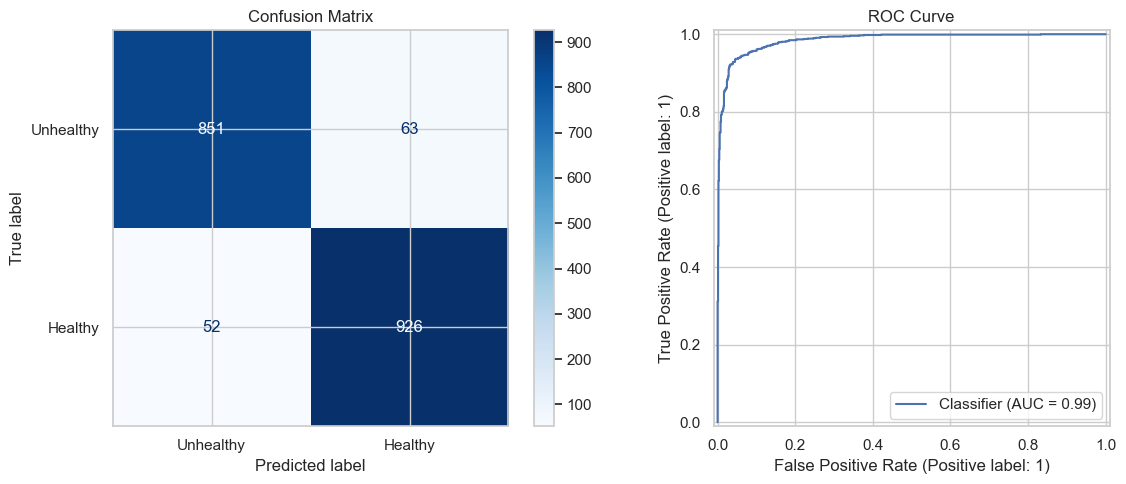

In [10]:
best_model = max([rf_search, svm_search], key=lambda s: s.best_score_)
print("Selected:", "RandomForest" if best_model is rf_search else "SVM")

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["0 Unhealthy", "1 Healthy"], digits=3))
print("ROC AUC:", round(roc_auc_score(y_test, y_proba), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax[0], cmap="Blues",
                                        display_labels=["Unhealthy", "Healthy"])
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax[1])
ax[0].set_title("Confusion Matrix"); ax[1].set_title("ROC Curve")
plt.tight_layout(); plt.show()

## Step 11: Feature importance
Permutation importance is the more reliable of the two.

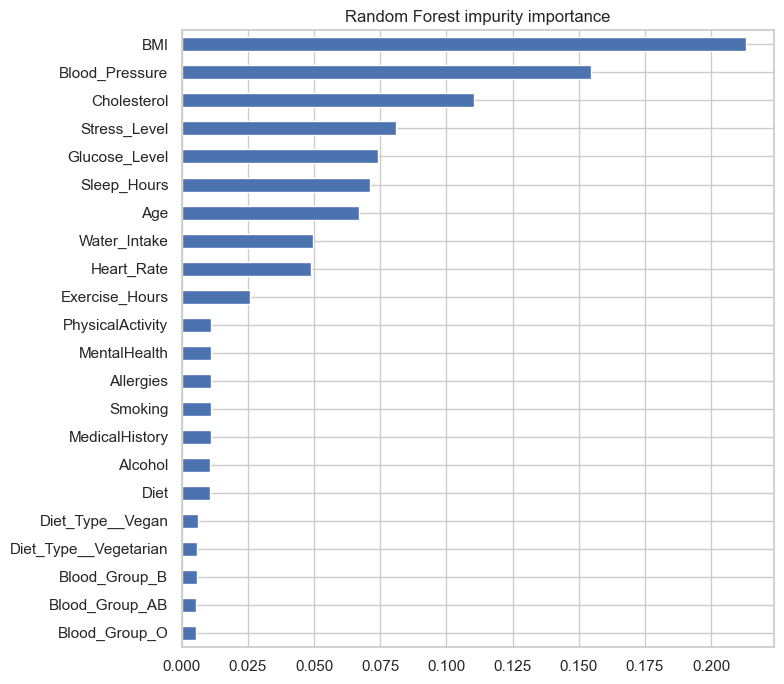

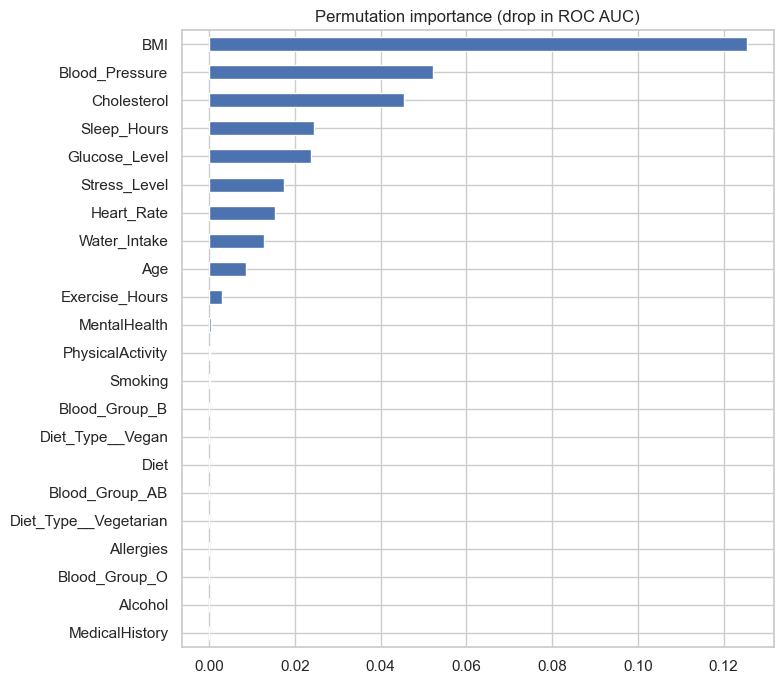

BMI               0.1255
Blood_Pressure    0.0521
Cholesterol       0.0453
Sleep_Hours       0.0245
Glucose_Level     0.0238
Stress_Level      0.0174
Heart_Rate        0.0152
Water_Intake      0.0127
Age               0.0085
Exercise_Hours    0.0030
dtype: float64


In [11]:
rf_best = rf_search.best_estimator_

imp = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 7), title="Random Forest impurity importance")
plt.tight_layout(); plt.show()

perm = permutation_importance(rf_best, X_test, y_test, n_repeats=5,
                              scoring="roc_auc", random_state=42, n_jobs=-1)
pi = pd.Series(perm.importances_mean, index=X.columns).sort_values()
pi.plot(kind="barh", figsize=(8, 7), title="Permutation importance (drop in ROC AUC)")
plt.tight_layout(); plt.show()

print(pi.sort_values(ascending=False).head(10).round(4))

## Step 12 (optional): Overfitting check and threshold tuning
Lowering the threshold catches more unhealthy participants at the cost of precision.

In [12]:
print("Train F1:", round(f1_score(y_train, rf_best.predict(X_train)), 3),
      "| Test F1:", round(f1_score(y_test, rf_best.predict(X_test)), 3))

# Class 0 (Unhealthy) is the one we most want to catch.
p_unhealthy = rf_best.predict_proba(X_test)[:, 0]
for t in [0.3, 0.4, 0.5]:
    pred = np.where(p_unhealthy >= t, 0, 1)
    rep = classification_report(y_test, pred, output_dict=True)
    print(f"threshold {t}: recall(Unhealthy)={rep['0']['recall']:.3f}, "
          f"precision(Unhealthy)={rep['0']['precision']:.3f}")

Train F1: 1.0 | Test F1: 0.94
threshold 0.3: recall(Unhealthy)=0.973, precision(Unhealthy)=0.846
threshold 0.4: recall(Unhealthy)=0.947, precision(Unhealthy)=0.911
threshold 0.5: recall(Unhealthy)=0.918, precision(Unhealthy)=0.950


## Step 13: Save the final model

In [13]:
joblib.dump(best_model.best_estimator_, "best_health_model.joblib")
print("Saved best_health_model.joblib")

Saved best_health_model.joblib


In [ ]:
pip install -r requirements.txt


In [ ]:
streamlit run app.py